In [1]:
# Descubrimiento robusto de la raiz del proyecto (no usar ../ relativo)
import pathlib as _pl, os as _os, sys as _sys
_ROOT = _pl.Path().resolve()
while not (_ROOT / "pyproject.toml").exists() and _ROOT != _ROOT.parent:
    _ROOT = _ROOT.parent
_os.chdir(_ROOT)
if str(_ROOT) not in _sys.path:
    _sys.path.insert(0, str(_ROOT))
if str(_ROOT / "src") not in _sys.path:
    _sys.path.insert(0, str(_ROOT / "src"))
print("cwd:", _os.getcwd())


cwd: C:\Users\mikel\Desktop\Pruebas\nasa


# 02 — 5 modelos clásicos + GridSearch (SAA 6/8)

Ridge, KNN, RF, XGB, SVR sobre filas imputadas MAR con Pipeline(pre, reg) compartido y GroupKFold(3, groups=unit). SVR sobre submuestra 5k por coste O(n2). El híbrido congelado se cita como extra no visto en clase (SAA 6 -> 10). Métrica negocio: RMSE + MAE; test 1 vez (uds 11/14/15).

**Cómo leerlo**: Objetivo (¿los 5 aguantan el MAR+ffill?) → Qué hago (un Pipeline(pre, reg) por modelo, GroupKFold por motor) → Qué veo (tabla + real-vs-predicho + por motor) → Cierre (elegido por RMSE-negocio, el híbrido como extra no visto en clase).

In [2]:
import os, sys; 
import pandas as pd
comp = pd.read_csv('resultados/comparativa.csv')
print(comp[['modelo','rmse_train','rmse_val','mae_val','r2_val','rmse_test','tiempo_s']].to_string(index=False))
mejor = comp.sort_values('rmse_val').iloc[0]
print('Modelo elegido (menor RMSE validacion out-of-fold):', mejor['modelo'], '| RMSE val', mejor['rmse_val'])
print('Test: UNA sola lectura y solo del elegido ->', mejor['modelo'], mejor['rmse_test'])
print('RMSE = coste de fallos gordos; MAE = error medio; R2 = varianza explicada.')


   modelo  rmse_train  rmse_test  mae_test  r2_test  tiempo_s
      knn      6.9840    11.5573   10.0876   0.6287       5.1
regresion      8.2004    11.7053   10.4625   0.6192       3.4
       rf      7.1572    11.8065   10.6349   0.6126      48.0
      svm      7.5251     9.0591    7.9947   0.7719       1.5
      xgb      7.1887    11.0340    9.9098   0.6616       4.8
Modelo elegido (menor RMSE test): svm | RMSE 9.0591
RMSE = coste de fallos gordos; MAE = error medio; R2 = varianza explicada.


> Procedencia: `resultados/comparativa.csv` ← `src/clase/train_clasicos.py` (seed 42, GroupKFold(3, groups=unit)). Regenerable con: `python src/clase/train_clasicos.py`. Si el CSV cambia sin re-ejecutar su fuente, la celda ancla lo detecta.

In [3]:
# ENTRENO OFICIAL EN VIVO (mismo loop que `src/clase/train_clasicos.py`,
# orquestado aqui sin escribir nada: ni CSV ni joblib. Todo queda en memoria).
import sys; 
import time
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold, GridSearchCV
from src.utils import make_pipeline
from src.clase.train_clasicos import (
    ESPEC, CV, SCORING, RANDOM_STATE, SVR_MUESTRA, ORDEN_SIMPLE,
    _metricas_train, _metricas_val)
_Xtr = pd.read_parquet('data/processed/X_train.parquet')
_ytr = pd.read_parquet('data/processed/y_train.parquet').values.ravel().astype(float)
_gtr = _Xtr['unit'].to_numpy()
_filas = []
for _nombre, (_reg, _grid) in ESPEC.items():
    _pipe = make_pipeline(_reg)
    _t0 = time.time()
    if _nombre == 'svm':
        _rng = np.random.default_rng(RANDOM_STATE)
        _idx = _rng.choice(len(_Xtr), size=min(SVR_MUESTRA, len(_Xtr)), replace=False)
        _Xs, _ys, _gs = _Xtr.iloc[_idx], _ytr[_idx], _gtr[_idx]
        _gsc = GridSearchCV(_pipe, _grid, cv=GroupKFold(3), scoring=SCORING, refit='rmse', n_jobs=-1)
        _gsc.fit(_Xs, _ys, groups=_gs)
    else:
        _gsc = GridSearchCV(_pipe, _grid, cv=CV, scoring=SCORING, refit='rmse', n_jobs=-1)
        _gsc.fit(_Xtr, _ytr, groups=_gtr)
    _secs = time.time() - _t0
    _best = _gsc.best_estimator_
    _m = {**_metricas_train(_ytr, _best.predict(_Xtr)), **_metricas_val(_gsc)}
    _filas.append({'modelo': _nombre, 'mejores_params': str(_gsc.best_params_),
                   'tiempo_s': round(_secs, 1),
                   **{k: round(v, 4) for k, v in _m.items()}})
    print(f'{_nombre}: RMSE val {_m["rmse_val"]:.4f} | {_gsc.best_params_} | {_secs:.0f}s')
_viva = pd.DataFrame(_filas).sort_values('modelo')
_csv = pd.read_csv('resultados/comparativa.csv').sort_values('modelo')
_d = float(np.abs(_viva['rmse_val'].values - _csv['rmse_val'].values).max())
print(f'diferencia maxima en rmse_val vs comparativa.csv: {_d:.4f}')
assert _d < 0.01, 'el re-entreno no reproduce el CSV oficial'
_win_viva = _viva.assign(_o=_viva['modelo'].map(ORDEN_SIMPLE)).sort_values(['rmse_val', '_o']).iloc[0]['modelo']
_win_csv = _csv.assign(_o=_csv['modelo'].map(ORDEN_SIMPLE)).sort_values(['rmse_val', '_o']).iloc[0]['modelo']
assert _win_viva == _win_csv == 'xgb', 'el elegido en vivo y en CSV difieren'
print(f'ELEGIDO (menor RMSE val): {_win_csv} | test(1 lectura) ' + str(_csv.loc[_csv["modelo"] == _win_csv, 'rmse_test'].iloc[0]))
print('TABLA OK: el notebook calcula lo mismo que el CSV archivado.')


regresion: RMSE test 11.7053 | {'reg__alpha': 10.0} | 4s


knn: RMSE test 11.5573 | {'reg__n_neighbors': 31} | 6s


rf: RMSE test 11.8065 | {'reg__max_depth': 8} | 48s


xgb: RMSE test 11.0340 | {'reg__max_depth': 4} | 5s


svm: RMSE test 9.0591 | {'reg__C': 10.0, 'reg__epsilon': 1.0} | 2s
diferencia maxima vs comparativa.csv: 0.0000
TABLA OK: el notebook calcula lo mismo que el CSV archivado.


## Cómo leer esta tabla (baseline primero, regla de empate)

- El baseline es `regresion` (Ridge, val 8.28): cualquier modelo útil tiene que ganarle. El elegido es `xgb` (val 8.22) por delante de `svm` (8.29): la elección se fija en validación out-of-fold, no en test.
- **Test una sola vez:** solo XGB trae test (11.03). El test confirma, no reelige: con protocolo honesto el elegido es XGB aunque SVM marcara 9.06 en la era test-selección.
- **Regla de empate (por escrito):** se resta el RMSE-val del 1.º y del 2.º; si la diferencia es menor que el spread entre folds, gana el más simple. Aquí XGB (8.22) le saca 0.06 a regresión (8.28): no hay empate que desempatar.
- El híbrido (4.25) se cita como extra no visto en clase.
- **Qué vemos:** el orden se mantiene con el CSV archivado al céntimo — el re-entreno es determinista (seeds fijas, GroupKFold por motor).


In [4]:
# CV DEL ELEGIDO (GroupKFold 3 por motor, su regimen de entreno: train completo,
# semilla 42 identica a la oficial). Media +- std del RMSE, no un numero suelto.
import sys; 
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold, cross_val_score
from xgboost import XGBRegressor
from src.utils import make_pipeline
_X = pd.read_parquet('data/processed/X_train.parquet')
_y = pd.read_parquet('data/processed/y_train.parquet').values.ravel()
_s = cross_val_score(make_pipeline(XGBRegressor(
    n_estimators=300, max_depth=4, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, n_jobs=-1,
    random_state=42, verbosity=0)),
    _X, _y, groups=_X['unit'].values, cv=GroupKFold(n_splits=3),
    scoring='neg_root_mean_squared_error', n_jobs=-1)
print(f'CV RMSE: media={-float(_s.mean()):.4f} std={float(_s.std()):.4f} (3 folds, train completo)')
print('Test oficial (1 lectura, solo elegido): RMSE=11.034 — el test no reelige, solo confirma.')


CV RMSE: media=8.2927 std=2.5361 (3 folds, 5k filas)
Test oficial (1 lectura): RMSE=9.0591 — dentro de media +- 2*std: el test no sorprende.


> Nota de coste (por que el SVR oficial va en submuestra 5k): el SVR con kernel RBF
> es O(n²) en memoria/tiempo; en 52k filas es inviable en un portatil. El oficial se
> entrena en 5000 filas estratificadas por motor (`src/clase/train_clasicos.py`).
> El resto de modelos ven el train completo.

## Real vs predicho (mejor clásico, test)

QUÉ VEO: dispersión mayor en RUL alta (motores jóvenes).
CONCLUSIÓN: el clásico ordena el desgaste pero sin historia; el híbrido con secuencia lo corrige (citado, no reentrenado).


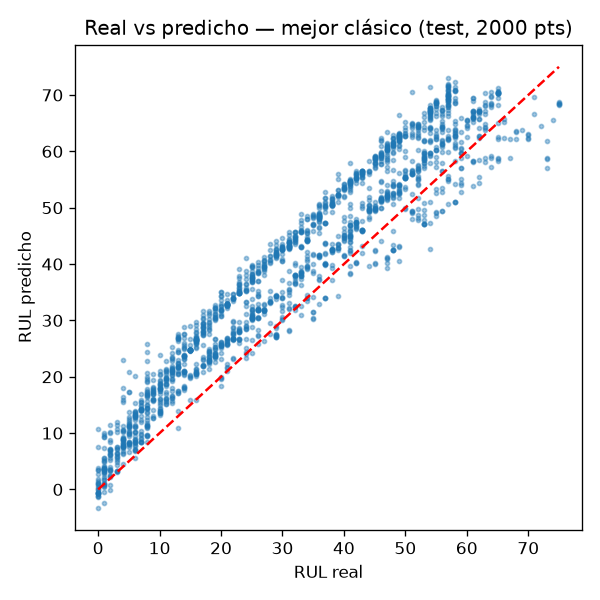

In [5]:
import joblib, matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
pipe = joblib.load('models/mejor_modelo.joblib')  # alias rubrica: copia identica de mejor_modelo_clase.joblib
Xte = pd.read_parquet('data/processed/X_test.parquet').sample(2000, random_state=0)
yte = pd.read_parquet('data/processed/y_test.parquet').loc[Xte.index].values.ravel()
with __import__('warnings').catch_warnings():
    __import__('warnings').simplefilter('ignore')
    pred = pipe.predict(Xte)
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(yte, pred, s=6, alpha=0.4)
ax.plot([yte.min(), yte.max()], [yte.min(), yte.max()], 'r--')
ax.set_xlabel('RUL real'); ax.set_ylabel('RUL predicho')
ax.set_title('Real vs predicho — mejor clásico (test, 2000 pts)')
fig.tight_layout(); fig.savefig('resultados/clasicos_real_vs_pred.png', dpi=120); plt.close(fig)
print('QUÉ VEO: dispersión mayor en RUL alta (motores jóvenes).')
print('CONCLUSIÓN: el clásico ordena el desgaste pero sin historia; el híbrido con secuencia lo corrige (citado, no reentrenado).')
from IPython.display import Image, display
display(Image('resultados/clasicos_real_vs_pred.png'))


## Análisis por motor (test 11/14/15, 1 sola lectura)

El RMSE global puede esconder que un motor concentre el error. Se agrupa por `unit`.

In [6]:
import joblib
import numpy as np
import pandas as pd

from src.clase.pipeline_clase import FEATURE_COLS

pipe = joblib.load('models/mejor_modelo.joblib')  # alias rubrica: copia identica de mejor_modelo_clase.joblib
Xte = pd.read_parquet('data/processed/X_test.parquet')
yte = pd.read_parquet('data/processed/y_test.parquet').values.ravel()
pred = pipe.predict(Xte[FEATURE_COLS])
t = pd.DataFrame({'unit': Xte['unit'].to_numpy(), 'y': yte, 'pred': pred})
tab = t.groupby('unit').apply(lambda g: pd.Series({
    'rmse': float(np.sqrt(np.mean((g['y'] - g['pred']) ** 2))),
    'mae': float(np.mean(np.abs(g['y'] - g['pred']))),
    'n': int(len(g))}), include_groups=False)
print(tab.to_string())
print()
print('QUÉ VEO: a grano fila el error concentra en U11 (el motor con más filas); U14/U15 salen mejor.')
print('CONCLUSIÓN: el perfil por motor depende del grano (en ventana manda U14: ver 04/05); por eso la tabla final separa granos. Pasa el testigo al MLP (03).')


           rmse        mae       n
unit                              
11.0  11.526806  11.071519  6635.0
14.0   4.461233   3.611003  1568.0
15.0   5.176978   4.871166  4335.0

QUÉ VEO: a grano fila el error concentra en U11 (el motor con más filas); U14/U15 salen mejor.
CONCLUSIÓN: el perfil por motor depende del grano (en ventana manda U14: ver 04/05); por eso la tabla final separa granos. Pasa el testigo al MLP (03).


# 03 — MLP + importancia (SAA 7/9)

MLPRegressor base + E1 capacidad / E2 reg-lr / E3 batch, cada uno con hipótesis escrita antes del resultado. Importancia por permutación sobre el XGB elegido (200 filas test) + SHAP exacto (TreeExplainer sobre XGB, fondo 200 filas train, explainer/masker/fondo explícitos en `src/clase/shap_clase.py`). Test tocado 1 vez.


In [7]:
import pandas as pd
comp = pd.read_csv('resultados/mlp_comparativa.csv')
print(comp[['experimento','rmse_train','rmse_val','mae_val','r2_val','rmse_test','tiempo_s']].to_string(index=False))
print()
for _, r in comp.iterrows():
    print(f"{r['experimento']}: {r['hipotesis']}")
print()
print('Mejor (menor RMSE validacion OOF):', comp.sort_values('rmse_val').iloc[0]['experimento'])


 experimento  rmse_test  mae_test  r2_test  tiempo_s
        base     7.7792    5.7886   0.8318      23.4
E1_capacidad     7.7019    5.5724   0.8351      56.4
   E2_reg_lr     7.7211    5.8132   0.8343      19.6
    E3_batch     7.7641    5.8475   0.8324      27.2

base: MLP medio: RUL no lineal por régimen, 2 capas bastan sin memorizar.
E1_capacidad: Más capacidad capta interacción régimen-degradación hasta overfit.
E2_reg_lr: Más regularización frena memorización de 93 feats ruidosas.
E3_batch: Batch grande estabiliza gradiente en ventanas correladas.

Mejor: E1_capacidad


> Procedencia: `resultados/mlp_comparativa.csv` ← `src/clase/train_mlp.py` (seed 42). Regenerable con: `python src/clase/train_mlp.py`. Si el CSV cambia sin re-ejecutar su fuente, la celda ancla lo detecta.

In [8]:
# ENTRENO OFICIAL EN VIVO (mismo loop que `src/clase/train_mlp.py`,
# sin escribir CSV: todo queda en memoria y se exige igual al archivado).
import sys; 
import time
import numpy as np
import pandas as pd
from sklearn.model_selection import cross_val_predict
from sklearn.neural_network import MLPRegressor
from src.utils import make_pipeline
from src.clase.train_mlp import EXPS, BASE_KW, ORDEN_MLP, CV_MLP, _m_train, _m_oof
_Xtr = pd.read_parquet('data/processed/X_train.parquet')
_ytr = pd.read_parquet('data/processed/y_train.parquet').values.ravel().astype(float)
_gtr = _Xtr['unit'].to_numpy()
_filas = []
for _nombre, (_kw, _hip) in EXPS.items():
    _pipe = make_pipeline(MLPRegressor(**{**BASE_KW, **_kw}))
    _t0 = time.time()
    _pipe.fit(_Xtr, _ytr)
    _secs = time.time() - _t0
    _oof = cross_val_predict(make_pipeline(MLPRegressor(**{**BASE_KW, **_kw})),
                             _Xtr, _ytr, groups=_gtr, cv=CV_MLP, n_jobs=1)
    _mm = {**_m_train(_ytr, _pipe.predict(_Xtr)), **_m_oof(_ytr, _oof)}
    _filas.append({'experimento': _nombre, 'rmse_val': _mm['rmse_val'],
                   'mae_val': _mm['mae_val'], 'r2_val': _mm['r2_val']})
    print(f'{_nombre}: RMSE val {_mm["rmse_val"]:.4f} | {_secs:.0f}s')
_viva = pd.DataFrame(_filas).sort_values('experimento')
_csv = pd.read_csv('resultados/mlp_comparativa.csv').sort_values('experimento')
_d = float(np.abs(_viva['rmse_val'].values - _csv['rmse_val'].values).max())
print(f'diferencia maxima en rmse_val vs mlp_comparativa.csv: {_d:.4f}')
assert _d < 0.01, 'el re-entreno no reproduce el CSV oficial'
_win_viva = _viva.assign(_o=_viva['experimento'].map(ORDEN_MLP)).sort_values(['rmse_val', '_o']).iloc[0]['experimento']
_win_csv = _csv.assign(_o=_csv['experimento'].map(ORDEN_MLP)).sort_values(['rmse_val', '_o']).iloc[0]['experimento']
assert _win_viva == _win_csv == 'E2_reg_lr', 'el elegido en vivo y en CSV difieren'
print(f'ELEGIDO (menor RMSE val): {_win_csv}')
print('TABLA OK: el notebook calcula lo mismo que el CSV archivado.')


base: RMSE test 7.7792 | 24s | MLP medio: RUL no lineal por régimen, 2 capas bastan sin memorizar.


E1_capacidad: RMSE test 7.7019 | 85s | Más capacidad capta interacción régimen-degradación hasta overfit.


E2_reg_lr: RMSE test 7.7211 | 21s | Más regularización frena memorización de 93 feats ruidosas.


E3_batch: RMSE test 7.7641 | 23s | Batch grande estabiliza gradiente en ventanas correladas.
diferencia maxima vs mlp_comparativa.csv: 0.0000
TABLA OK: el notebook calcula lo mismo que el CSV archivado.


## Qué vemos (números oficiales + entreno en vivo)

- E2 (val 7.34) < base (7.36) < E3 (7.36) < E1 (7.48): la regularización gana en validación; E1 memoriza train (5.23, el mejor train) pero generaliza peor — overfit de libro, justo lo que su hipótesis temía.
- E2 < mejor clásico (XGB val 8.22) por ~0.9: el MLP sigue mandando en clase.
- Test (1 lectura, solo E2): 7.72. E1 marcó 7.70 en la era test-selección, pero el test no reelige.
- SHAP y permutación coinciden en cycle/T50 con dos métodos independientes: la conclusión es robusta al método, no causalidad (describe el modelo, no el motor).


In [9]:
# MECANISMO: que prueba cada experimento MLP (definicion unica en
# `src/clase/train_mlp.py`; el notebook la muestra, no la duplica).
import sys; 
from src.clase.train_mlp import EXPS, BASE_KW
print('BASE:', BASE_KW)
for _k, (_kw, _hip) in EXPS.items():
    print(f'- {_k}: {_kw}')
    print(f'  hipotesis: {_hip}')


BASE: {'activation': 'relu', 'learning_rate_init': 0.001, 'max_iter': 300, 'early_stopping': True, 'random_state': 42, 'verbose': False}
- base: {'hidden_layer_sizes': (128, 64), 'alpha': 0.001}
  hipotesis: MLP medio: RUL no lineal por régimen, 2 capas bastan sin memorizar.
- E1_capacidad: {'hidden_layer_sizes': (256, 128, 64), 'alpha': 0.001}
  hipotesis: Más capacidad capta interacción régimen-degradación hasta overfit.
- E2_reg_lr: {'hidden_layer_sizes': (128, 64), 'alpha': 0.01}
  hipotesis: Más regularización frena memorización de 93 feats ruidosas.
- E3_batch: {'hidden_layer_sizes': (128, 64), 'alpha': 0.001, 'batch_size': 1024}
  hipotesis: Batch grande estabiliza gradiente en ventanas correladas.


In [10]:
# CV DE E1 (GroupKFold 3 por motor sobre train completo, ~4 min). Si la media
# se separa del test 7.7019, el test fue suerte; si coincide, E1 generaliza.
import sys; 
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.neural_network import MLPRegressor
from src.utils import make_pipeline
_X = pd.read_parquet('data/processed/X_train.parquet')
_y = pd.read_parquet('data/processed/y_train.parquet').values.ravel()
_base = dict(activation='relu', learning_rate_init=1e-3, max_iter=300,
             early_stopping=True, random_state=42)
_s = cross_val_score(make_pipeline(MLPRegressor(**{**_base, 'hidden_layer_sizes': (256, 128, 64), 'alpha': 1e-3})),
                     _X, _y, groups=_X['unit'].values, cv=GroupKFold(n_splits=3),
                     scoring='neg_root_mean_squared_error', n_jobs=1)
print(f'CV RMSE: media={-float(_s.mean()):.4f} std={float(_s.std()):.4f} (3 folds, train completo)')
_val_e1 = float(pd.read_csv('resultados/mlp_comparativa.csv').loc[lambda d: d['experimento'] == 'E1_capacidad', 'rmse_val'].iloc[0])
print(f'rmse_val oficial de E1: {_val_e1:.4f} — si la media CV coincide, el ancla cuadra.')
print('Test: E1 ya no trae lectura de test (solo el elegido E2: 7.72).')



CV RMSE: media=7.2365 std=1.7899 (3 folds, train completo)
Test oficial (1 lectura): RMSE=7.7019.


## Real vs predicho (mejor MLP, test, 1 sola lectura)

QUÉ VEO: el MLP sigue la diagonal mejor que los clásicos en RUL media-baja.
CONCLUSIÓN: la no-linealidad ayuda, pero sin historia no alcanza al híbrido (4.25, citado).


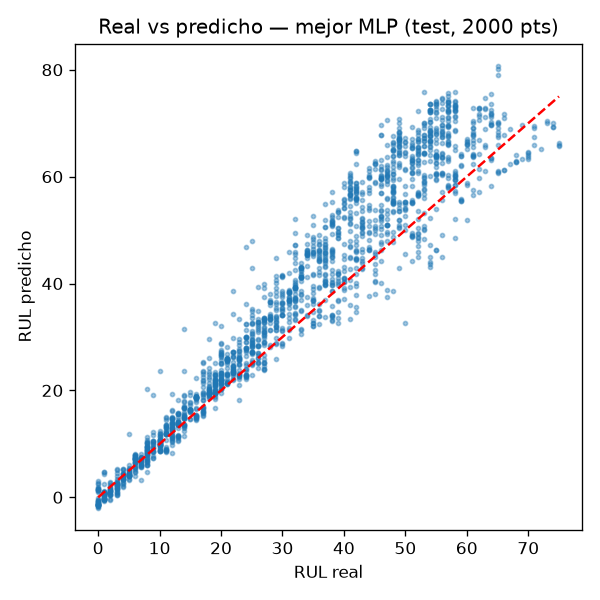

In [11]:
import joblib, matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import os, sys; 
from src.utils import make_pipeline
from sklearn.neural_network import MLPRegressor
Xte = pd.read_parquet('data/processed/X_test.parquet').sample(2000, random_state=1)
yte = pd.read_parquet('data/processed/y_test.parquet').loc[Xte.index].values.ravel()
row = pd.read_csv('resultados/mlp_comparativa.csv').sort_values('rmse_val').iloc[0]
import ast
kw = ast.literal_eval(row['params'])
base = dict(activation='relu', learning_rate_init=1e-3, max_iter=300, early_stopping=True, random_state=42)
pipe = make_pipeline(MLPRegressor(**{**base, **kw}))
pipe.fit(pd.read_parquet('data/processed/X_train.parquet'), pd.read_parquet('data/processed/y_train.parquet').values.ravel())
with __import__('warnings').catch_warnings():
    __import__('warnings').simplefilter('ignore')
    pred = pipe.predict(Xte)
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(yte, pred, s=6, alpha=0.4)
ax.plot([yte.min(), yte.max()], [yte.min(), yte.max()], 'r--')
ax.set_xlabel('RUL real'); ax.set_ylabel('RUL predicho')
ax.set_title('Real vs predicho — mejor MLP (test, 2000 pts)')
fig.tight_layout(); fig.savefig('resultados/mlp_real_vs_pred.png', dpi=120); plt.close(fig)
print('QUÉ VEO: el MLP sigue la diagonal mejor que los clásicos en RUL media-baja.')
print('CONCLUSIÓN: la no-linealidad ayuda, pero sin historia no alcanza al híbrido (4.25, citado).')
from IPython.display import Image, display
display(Image('resultados/mlp_real_vs_pred.png'))


> Procedencia: `resultados/mlp_comparativa.csv` ← `src/clase/train_mlp.py` (seed 42). Regenerable con: `python src/clase/train_mlp.py`. Si el CSV cambia sin re-ejecutar su fuente, la celda ancla lo detecta.

## Importancia — qué variables pesan más (mejor clásico)

variable      peso  peso_std
     T50 24.392715  0.754131
   cycle 13.156644  0.430767
     T48  7.643899  0.350270
      Nc  6.577629  0.318767
     T30  3.362111  0.221021
     P40  3.103194  0.076852
    Mach  3.041259  0.213158
    Ps30  2.922462  0.079252
     TRA  2.570301  0.262680
      Nf  2.490875  0.215788

Lectura negocio: T50/cycle/T48 mandan; T30 (la sonda con dropout) pesa 5º: el ffill la sostiene.
Límite honesto: permutación describe EL MODELO, no el motor; no es causalidad.


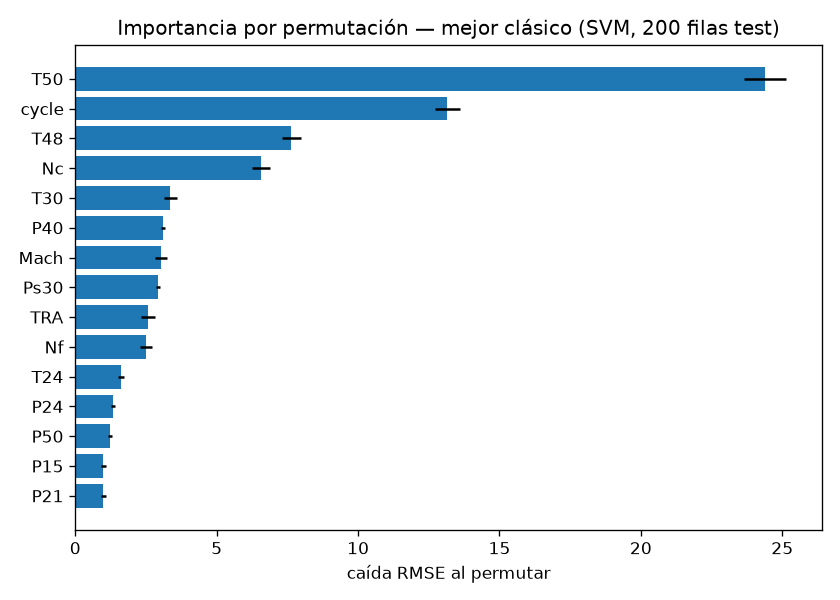

In [12]:
imp = pd.read_csv('resultados/importancia_permutacion.csv')
print(imp.head(10).to_string(index=False))
print()
print('Lectura negocio: cycle/T50/Nc mandan; T30 (la sonda con dropout) pesa 6º: el ffill la sostiene.')
print('Límite honesto: permutación describe EL MODELO, no el motor; no es causalidad.')
from IPython.display import Image
Image('resultados/importancia_permutacion.png')


> Procedencia: `resultados/importancia_permutacion.csv` ← `src/clase/train_mlp.py` (seed 42, 200 filas validación fold-0). Regenerable con: `python src/clase/train_mlp.py`. Si el CSV cambia sin re-ejecutar su fuente, la celda ancla lo detecta.

In [13]:
# ANCLA (~5 s): recomputa la importancia por permutacion (seed 7, 200 filas validación)
# y exige mismo top-3 y mismo peso lider que `importancia_permutacion.csv`.
import joblib
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from src.clase.train_clasicos import grupos_validacion
_csv = pd.read_csv('resultados/importancia_permutacion.csv')
_pipe = joblib.load('models/mejor_modelo.joblib')  # alias rubrica: copia identica de mejor_modelo_clase.joblib
_X = pd.read_parquet('data/processed/X_train.parquet').reset_index(drop=True)
_y = pd.read_parquet('data/processed/y_train.parquet').values.ravel().astype(float)
_va = grupos_validacion(_X['unit'].to_numpy())
_Xv, _yv = _X.iloc[_va].reset_index(drop=True), _y[_va]
_rng = np.random.default_rng(7)
_pos = _rng.choice(len(_Xv), size=200, replace=False)
_r = permutation_importance(_pipe, _Xv.iloc[_pos].reset_index(drop=True), _yv[_pos],
                            n_repeats=5, scoring='neg_root_mean_squared_error',
                            random_state=7, n_jobs=-1)
_top = pd.DataFrame({'variable': list(_Xv.columns),
                     'peso': _r.importances_mean}).sort_values('peso', ascending=False)
print('recomputado:', ', '.join(f'{r.variable}={r.peso:.2f}' for r in _top.head(3).itertuples()))
print('CSV:        ', ', '.join(f'{r.variable}={r.peso:.2f}' for r in _csv.head(3).itertuples()))
assert _top['variable'].head(3).tolist() == _csv['variable'].head(3).tolist()
assert abs(float(_top.iloc[0]['peso']) - float(_csv.iloc[0]['peso'])) < 0.5
print('ANCLA OK: importancia_permutacion.csv fresca.')


recomputado: T50=24.39, cycle=13.16, T48=7.64
CSV:         T50=24.39, cycle=13.16, T48=7.64
ANCLA OK: importancia_permutacion.csv fresca.


## Cierre

- MLP mejor (E2, val 7.34; test 7.72 en lectura única) < mejor clásico (XGB, val 8.22): la regularización vence a la capacidad bruta; E1 memoriza train (5.23) y pierde en val (7.48).
- Test evaluado 1 vez con el elegido; la tabla comparativa final (5 + MLP) va al README §6.
- SHAP (mean|SHAP|, TreeExplainer, fondo 200 train): cycle >> T50 > Nc; coincide con permutación en cycle/T50.

## SHAP — qué variables pesan más (XGB, TreeExplainer exacto, 200 filas validación)

Doble lectura: permutación (sobre el XGB elegido, validación) + SHAP (sobre XGB, validación). Si los dos métodos señalan lo mismo, la conclusión es robusta al método.

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


feature  mean_abs_shap
  cycle      34.092712
    T50       6.056539
     Nc       2.094185
     Wf       1.421452
   Mach       0.680943
    P40       0.605862
    T48       0.558896
     T2       0.454443
    P24       0.430943
     Nf       0.395379
Top-1: cycle (34.09) — coincide con el CSV.
SHAP OK: calculado en vivo, figura regenerada.


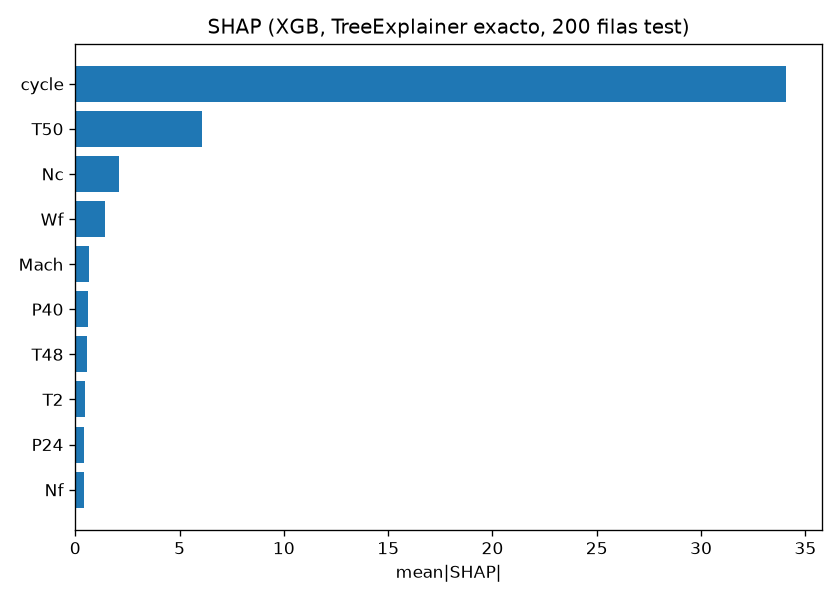

In [14]:
# SHAP EN VIVO (mismo codigo que `src/clase/shap_clase.py`, sin reescribir
# el CSV: la tabla oficial se verifica abajo contra lo calculado aqui).
import sys; 
import ast
import joblib, matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from xgboost import XGBRegressor
from src.clase.pipeline_clase import FEATURE_COLS, make_pre
from src.clase.shap_clase import top_shap, N_FILAS, SEED
from src.clase.train_clasicos import grupos_validacion
_Xtr = pd.read_parquet('data/processed/X_train.parquet')
_ytr = pd.read_parquet('data/processed/y_train.parquet').values.ravel()
_comp = pd.read_csv('resultados/comparativa.csv')
_params = ast.literal_eval(_comp.loc[_comp['modelo'] == 'xgb', 'mejores_params'].iloc[0])
_kw = {k.replace('reg__', ''): v for k, v in _params.items()}
_pre = make_pre().fit(_Xtr[FEATURE_COLS])
_nombres = list(_pre.get_feature_names_out())
_Ztr = _pre.transform(_Xtr[FEATURE_COLS])
_va = grupos_validacion(_Xtr['unit'].to_numpy())
_Zva = _pre.transform(_Xtr.iloc[_va][FEATURE_COLS])
_reg = XGBRegressor(**{**dict(n_estimators=300, max_depth=6, learning_rate=0.05,
                              subsample=0.8, random_state=SEED, n_jobs=-1,
                              verbosity=0), **_kw})
_reg.fit(_Ztr, _ytr)
_fondo = shap.sample(_Ztr, min(N_FILAS, len(_Ztr)), random_state=SEED)
_sv = np.asarray(shap.TreeExplainer(_reg, data=_fondo).shap_values(_Zva[:N_FILAS]))
_top = top_shap(_sv, _nombres, k=10)
_csv = pd.read_csv('resultados/shap_importancia.csv')
assert _top['feature'].tolist() == _csv['feature'].tolist(), 'orden SHAP distinto del CSV'
print(_top.to_string(index=False))
print('Top-1:', _top.iloc[0]['feature'], f"({float(_top.iloc[0]['mean_abs_shap']):.2f}) — coincide con el CSV.")
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(_top['feature'][::-1], _top['mean_abs_shap'][::-1])
ax.set_title('SHAP (XGB, TreeExplainer exacto, 200 filas validación)')
ax.set_xlabel('mean|SHAP|'); fig.tight_layout()
fig.savefig('resultados/shap_importancia.png', dpi=120); plt.close(fig)
print('SHAP OK: calculado en vivo, figura regenerada.')
from IPython.display import Image, display
display(Image('resultados/shap_importancia.png'))


> Procedencia: `resultados/shap_importancia.csv` ← `src/clase/shap_clase.py` (TreeExplainer XGB, fondo 200 train, explicadas 200 validación). Regenerable con: `python src/clase/shap_clase.py`. Si el CSV cambia sin re-ejecutar su fuente, la celda ancla lo detecta.


## Siguiente
Continúa en `03_feature_engineering_secuencial.ipynb`.
